# Model Training with Bootstrap Confidence Intervals

This notebook trains and compares three models for drone delivery on-time prediction.

The workflow is:
1. Stratified 80/20 train-validation split.
2. Hyperparameter tuning with `RandomizedSearchCV` on the training split only.
3. Evaluation on the untouched validation set.
4. Bootstrap confidence intervals for all metrics.
5. Violin plots of bootstrap metric distributions across all models.


## 1. Imports and paths

Imports the reusable pipeline-building blocks from `src/` (`load_drone_delivery_data`, `make_random_search`, the evaluation helpers) rather than redefining this logic inside the notebook, and sets up the output directories. Keeping modeling logic in `src/` instead of copy-pasted notebook cells means the exact same feature engineering, preprocessing, and pipeline construction used here is guaranteed to be reused identically in `03_Final_Model_Manager_Report.ipynb`, with no risk of the two notebooks silently drifting apart.


In [11]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_loading import load_drone_delivery_data
from src.modeling import make_random_search
from src.evaluation import (
    bootstrap_metric_distribution,
    summarize_bootstrap_metrics,
    make_formatted_metric_table,
    classification_report_df,
    plot_confusion_matrix,
    plot_roc_curve,
    plot_pr_curve,
    plot_metric_violins,
)

RANDOM_STATE = 42

DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "figures" / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
METRICS_DIR = OUTPUTS_DIR / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)


## 1b. Quick mode (for debugging)

In [12]:
QUICK_MODE = False  # <-- set to False for the real run

if QUICK_MODE:
    N_ITER = 3
    CV_SPLITS = 3
    N_BOOTSTRAP = 50
    TRAIN_SUBSAMPLE_FRAC = 0.1  # stratified fraction of the training split to use
else:
    N_ITER = 20
    CV_SPLITS = 5
    N_BOOTSTRAP = 1000
    TRAIN_SUBSAMPLE_FRAC = None

print(f"QUICK_MODE={QUICK_MODE} | N_ITER={N_ITER} | CV_SPLITS={CV_SPLITS} "
      f"| N_BOOTSTRAP={N_BOOTSTRAP} | TRAIN_SUBSAMPLE_FRAC={TRAIN_SUBSAMPLE_FRAC}")

QUICK_MODE=False | N_ITER=20 | CV_SPLITS=5 | N_BOOTSTRAP=1000 | TRAIN_SUBSAMPLE_FRAC=None


## 2. Load data

Uses the same `load_drone_delivery_data` loader as the EDA notebook, so both notebooks are guaranteed to read the same raw files the same way.


In [13]:
train, test, sample_submission = load_drone_delivery_data(DATA_DIR)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()


Loading: C:\Users\voula\Desktop\drone\data\raw\train.csv
Loading: C:\Users\voula\Desktop\drone\data\raw\test.csv
Loading: C:\Users\voula\Desktop\drone\data\raw\sample_submission.csv
Train shape: (40000, 11)
Test shape: (10000, 10)


,Id,distance_km,payload_kg,drone_model,slot_15min,wind_token,route_turns,alt_profile,landing_zone,operator_tag,on_time
0,1662,3.498,2.676,B,75,S-0/4,UUUUURLUD,0-0-0-0-1-1-1-1-1,LZ-146,safe,1
1,4591,2.209,1.480,B,30,SE-3/5,LLLULLLULLLDLUUULUUU,1-1-1-2-2-2-2-3-2-1-2-3-2-1-1-2-3-2-3-3,LZ-278,balanced,0
2,38756,1.876,0.267,A,26,N-3/5,RRURDDDRDDDRRURDRDRD,0-0-0-1-1-1-1-0-1-1-2-2-2-3-3-3-3-3-3-3,LZ-108,balanced,0
3,31027,1.496,0.510,A,9,E-10/18,LLDDDDLDDRDDRDDDDDDD,0-1-0-0-0-1-2-2-2-2-2-2-3-3-3-3-3-3-3-3,LZ-243,balanced,0
4,1642,2.041,0.240,B,52,SW-11/19,DRRDRRRURDRRDDLDDLDR,1-1-1-1-1-1-2-2-2-2-2-2-2-1-1-1-2-2-2-2,LZ-030,safe,0


## 3. Prepare features and target

Splits the raw training table into `X` (features) and `y` (the `on_time` target). All the feature engineering (wind/route/altitude parsing) and preprocessing (imputation, scaling, one-hot encoding) happens *inside* the modeling pipeline (`src/feature_engineering.py`, `src/preprocessing.py`), not here — so `X` at this point is still the raw dataframe. This keeps a clean separation between raw data and what the model does with it, since the same raw `X` can be fed to any of the three candidate pipelines.


In [14]:
TARGET = "on_time"

X = train.drop(columns=[TARGET])
y = train[TARGET]

print("X shape:", X.shape)
print("Target distribution:")
display(y.value_counts(normalize=True).to_frame("proportion"))


X shape: (40000, 10)
Target distribution:


,proportion
on_time,
1,0.5979
0,0.4021


## 4. Train-validation split

`stratify=y` keeps the same proportion of on-time vs. late deliveries in both the training and validation splits as in the full dataset. Without this, a random split could accidentally under- or over-represent the minority class in validation, making the reported metrics noisier and less trustworthy.

Hyperparameter tuning (next section) already uses cross-validation *within* the training split, but a separate validation set — never touched during tuning — is what gives an unbiased read on how the chosen model will perform on genuinely unseen data.


In [15]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

if TRAIN_SUBSAMPLE_FRAC is not None:
    X_train, _, y_train, _ = train_test_split(
        X_train,
        y_train,
        train_size=TRAIN_SUBSAMPLE_FRAC,
        stratify=y_train,
        random_state=RANDOM_STATE,
    )
    print(f"QUICK_MODE subsample applied: training split reduced to {X_train.shape[0]} rows")

print("Training split:", X_train.shape)
print("Validation split:", X_valid.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).to_frame("proportion"))

print("\nValidation target distribution:")
display(y_valid.value_counts(normalize=True).to_frame("proportion"))


Training split: (32000, 10)
Validation split: (8000, 10)

Training target distribution:


,proportion
on_time,
1,0.597906
0,0.402094



Validation target distribution:


,proportion
on_time,
1,0.597875
0,0.402125


## 5. Hyperparameter tuning

For each of the three candidate models (Logistic Regression, Random Forest, HistGradientBoosting), runs `RandomizedSearchCV` over its hyperparameter distribution, using only `X_train`/`y_train`.

With several hyperparameters per model, an exhaustive grid search becomes expensive fast. Randomized search samples `N_ITER` combinations instead of trying all of them, trading a small amount of thoroughness for a large speedup — reasonable here since we're comparing three different model families first, not squeezing the last 0.1% out of one. Tuning only uses the training split; it must never see the validation set, otherwise the validation metrics reported later would be optimistic.


In [16]:
MODEL_NAMES = [
    "logistic_regression",
    "random_forest",
    "hist_gradient_boosting",
]

# N_ITER and CV_SPLITS come from the QUICK_MODE cell above.
searches = {}
cv_results = []

for model_name in MODEL_NAMES:
    print("=" * 80)
    print(f"Tuning model: {model_name}")
    print("=" * 80)

    search = make_random_search(
        model_name=model_name,
        n_iter=N_ITER,
        scoring="roc_auc",
        cv_splits=CV_SPLITS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    search.fit(X_train, y_train)
    searches[model_name] = search

    cv_results.append({
        "model": model_name,
        "best_cv_roc_auc": search.best_score_,
        "best_params": search.best_params_,
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("best_cv_roc_auc", ascending=False)
display(cv_results_df)

cv_results_df.to_csv(METRICS_DIR / "cv_model_comparison.csv", index=False)


Tuning model: logistic_regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\voula\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


Tuning model: random_forest
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Tuning model: hist_gradient_boosting
Fitting 5 folds for each of 20 candidates, totalling 100 fits


,model,best_cv_roc_auc,best_params
0,logistic_regression,0.909723,"{'classifier__C': 0.4205156450913872, 'classif..."
2,hist_gradient_boosting,0.907308,{'classifier__l2_regularization': 0.9652553072...
1,random_forest,0.896762,"{'classifier__max_depth': 11, 'classifier__max..."


## 6. Bootstrap confidence intervals for all metrics

The table below reports each metric as:

```text
mean [95% CI lower, 95% CI upper]
```

A single accuracy/ROC-AUC number on one validation set doesn't say how much that number might shift on a different sample of the same data. Resampling the validation set with replacement `N_BOOTSTRAP` times and recomputing each metric each time gives a distribution, not just one number — which is what lets us later say that Logistic Regression and HistGradientBoosting are statistically indistinguishable rather than just eyeballing which point estimate is higher.


In [17]:
# N_BOOTSTRAP comes from the QUICK_MODE cell above.

all_bootstrap_wide = []
all_bootstrap_summary = []

for model_name, search in searches.items():
    print(f"Bootstrapping validation metrics for: {model_name}")

    model = search.best_estimator_
    y_proba = model.predict_proba(X_valid)[:, 1]

    boot_df = bootstrap_metric_distribution(
        y_true=y_valid,
        y_proba=y_proba,
        n_bootstrap=N_BOOTSTRAP,
        threshold=0.5,
        random_state=RANDOM_STATE,
    )

    boot_df["model"] = model_name
    all_bootstrap_wide.append(boot_df)

    summary_df = summarize_bootstrap_metrics(
        boot_df.drop(columns=["model"]),
        model_name=model_name,
        ci=95,
    )
    all_bootstrap_summary.append(summary_df)

bootstrap_wide_df = pd.concat(all_bootstrap_wide, ignore_index=True)
bootstrap_summary_df = pd.concat(all_bootstrap_summary, ignore_index=True)

formatted_metrics_table = make_formatted_metric_table(bootstrap_summary_df, decimals=3)

display(formatted_metrics_table)

bootstrap_wide_df.to_csv(METRICS_DIR / "bootstrap_metric_distributions_wide.csv", index=False)
bootstrap_summary_df.to_csv(METRICS_DIR / "bootstrap_metric_summary_long.csv", index=False)
formatted_metrics_table.to_csv(METRICS_DIR / "bootstrap_metric_summary_formatted.csv")


Bootstrapping validation metrics for: logistic_regression
Bootstrapping validation metrics for: random_forest
Bootstrapping validation metrics for: hist_gradient_boosting


metric,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
hist_gradient_boosting,"0.814 [0.805, 0.822]","0.839 [0.829, 0.850]","0.852 [0.842, 0.862]","0.845 [0.837, 0.853]","0.909 [0.903, 0.915]","0.942 [0.938, 0.947]"
logistic_regression,"0.813 [0.805, 0.821]","0.876 [0.866, 0.885]","0.800 [0.789, 0.811]","0.836 [0.828, 0.844]","0.911 [0.905, 0.917]","0.944 [0.940, 0.948]"
random_forest,"0.803 [0.794, 0.812]","0.872 [0.862, 0.882]","0.786 [0.774, 0.798]","0.827 [0.818, 0.835]","0.900 [0.894, 0.907]","0.937 [0.932, 0.941]"


### Note on model selection

The 95% bootstrap confidence intervals for `roc_auc` overlap heavily between `logistic_regression` (~0.911 [0.906, 0.917]) and `hist_gradient_boosting` (~0.909 [0.904, 0.915]) in the run these numbers came from. That means the difference in point estimates is not necessarily statistically meaningful — the honest claim is that the two models perform **comparably** on validation ROC-AUC, not that Logistic Regression is definitively the strongest. Logistic Regression is selected as the final model primarily for its **interpretability** (direct coefficients / odds ratios for the manager-facing report), with comparable predictive performance as a secondary justification, rather than purely for having the highest point estimate.

## 8. Violin plots for each metric across all models

The formatted CI table above summarizes each bootstrap distribution as three numbers (mean, lower, upper). The violin plots show the full shape of each distribution side by side, useful for seeing at a glance how much the three models' metric distributions overlap.


,bootstrap_iteration,model,metric,value
0,0,logistic_regression,accuracy,0.820000
1,1,logistic_regression,accuracy,0.813875
2,2,logistic_regression,accuracy,0.812750
3,3,logistic_regression,accuracy,0.815625
4,4,logistic_regression,accuracy,0.818750


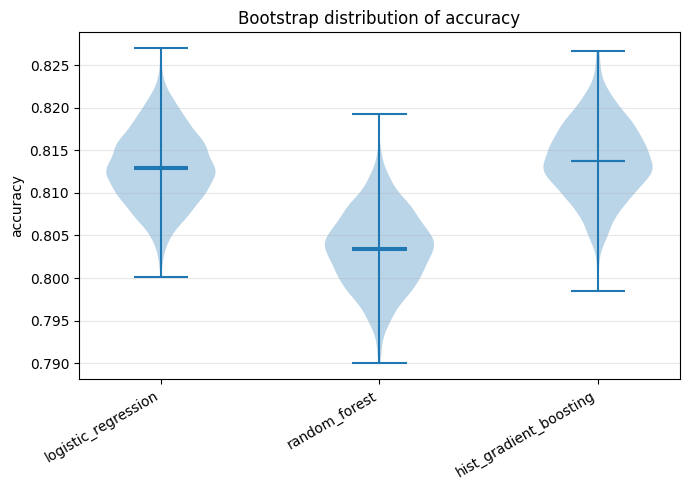

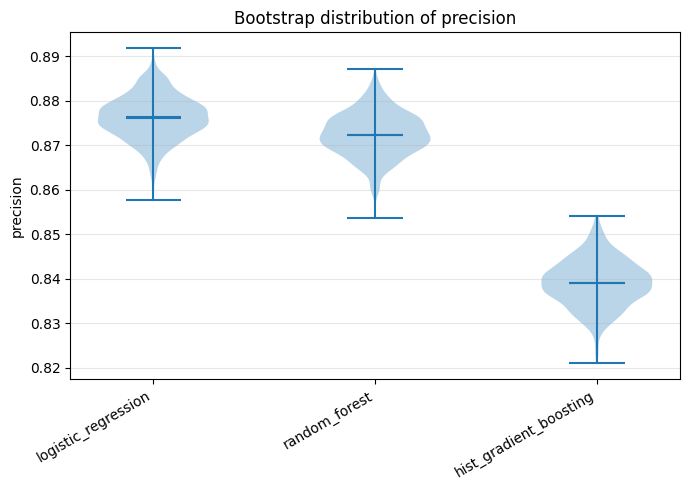

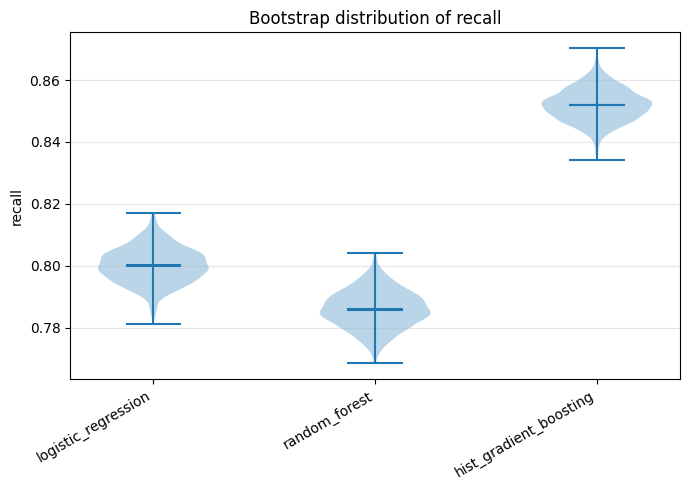

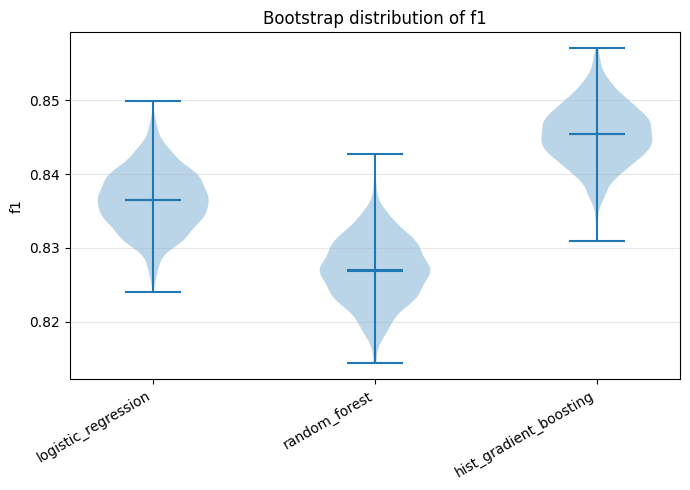

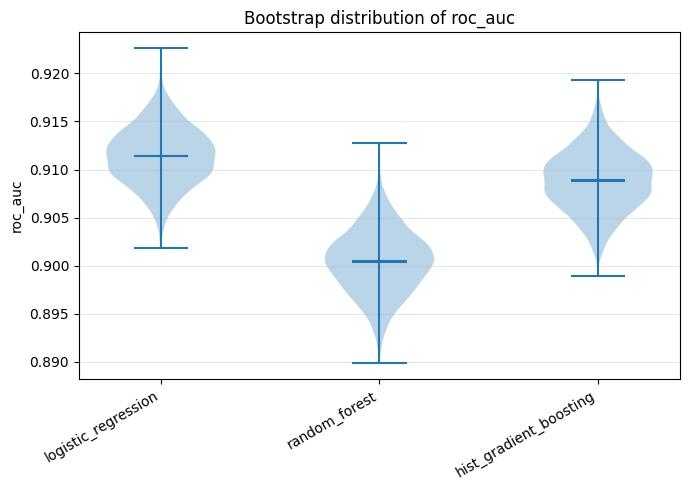

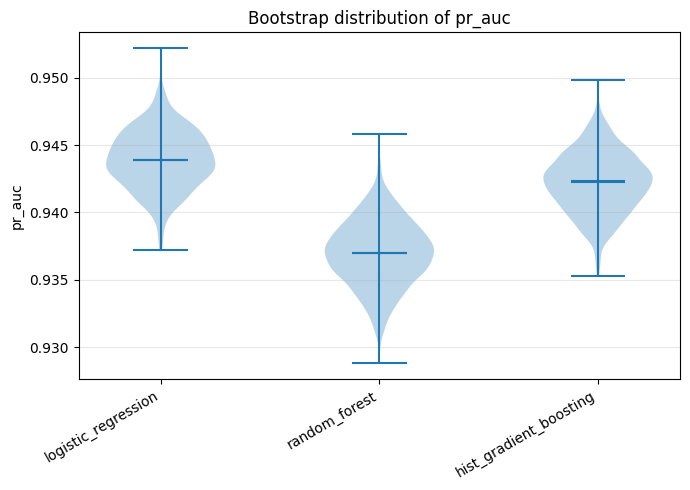

In [18]:
metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]

bootstrap_long_df = bootstrap_wide_df.melt(
    id_vars=["bootstrap_iteration", "model"],
    value_vars=metric_cols,
    var_name="metric",
    value_name="value",
)

display(bootstrap_long_df.head())

for metric in metric_cols:
    plot_metric_violins(
        bootstrap_long_df,
        metric=metric,
        save_path=FIGURES_DIR / f"bootstrap_violin_{metric}.png",
    )


## 9. Select final candidate model

Reuses the bootstrap ROC-AUC distributions computed in Section 6, sorted by mean, to pick the winning model — rather than computing a second, separate metrics table. The result is saved to `best_model_summary.json` so the next notebook can load the selected model/hyperparameters instead of having them hardcoded there.


In [19]:
# Model selection now reuses the bootstrap summary table computed above instead
# of computing a second, separate metrics table.
roc_auc_summary = (
    bootstrap_summary_df[bootstrap_summary_df["metric"] == "roc_auc"]
    .sort_values("mean", ascending=False)
    .reset_index(drop=True)
)

best_model_name = roc_auc_summary.loc[0, "model"]
best_search = searches[best_model_name]
best_model = best_search.best_estimator_

print("Best model based on bootstrap mean ROC-AUC:", best_model_name)
print("Best CV ROC-AUC:", best_search.best_score_)
print("Best parameters:")
display(best_search.best_params_)

# Saved as a plain dict (not a pandas-records list) so 03_Final_Model_Manager_Report.ipynb
# can load it directly with json.load() instead of hardcoding the model name/params.
# best_params_ keys use sklearn's np.float64 etc., so cast through float() for clean,
# portable JSON.
best_model_validation_metrics = (
    bootstrap_summary_df[bootstrap_summary_df["model"] == best_model_name]
    .set_index("metric")["mean"]
    .to_dict()
)

best_model_summary = {
    "best_model_name": best_model_name,
    "best_cv_roc_auc": float(best_search.best_score_),
    "best_params": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                    for k, v in best_search.best_params_.items()},
    "validation_metrics": best_model_validation_metrics,
    "quick_mode": QUICK_MODE,
}

with open(METRICS_DIR / "best_model_summary.json", "w", encoding="utf-8") as f:
    json.dump(best_model_summary, f, indent=4)

print("\nSaved best model summary to:", METRICS_DIR / "best_model_summary.json")
display(best_model_summary)


Best model based on bootstrap mean ROC-AUC: logistic_regression
Best CV ROC-AUC: 0.9097225415585394
Best parameters:


{'classifier__C': np.float64(0.4205156450913872), 'classifier__penalty': 'l2'}


Saved best model summary to: C:\Users\voula\Desktop\drone\outputs\metrics\best_model_summary.json


{'best_model_name': 'logistic_regression',
 'best_cv_roc_auc': 0.9097225415585394,
 'best_params': {'classifier__C': 0.4205156450913872,
  'classifier__penalty': 'l2'},
 'validation_metrics': {'accuracy': 0.8129927499999999,
  'precision': 0.8762188747890876,
  'recall': 0.8001796879571983,
  'f1': 0.8364595434797555,
  'roc_auc': 0.9113711983855023,
  'pr_auc': 0.943915874056898},
 'quick_mode': False}

## 10. Detailed evaluation of the selected model

A single ROC-AUC number can hide important detail, such as whether errors are concentrated on false positives or false negatives. The classification report (per-class precision/recall/F1), confusion matrix, ROC curve, and PR curve together give a fuller picture of exactly how the selected model behaves before it's carried into the final report.


,precision,recall,f1-score,support
0,0.736712,0.831520,0.781250,3217.00000
1,0.875944,0.800125,0.836320,4783.00000
accuracy,0.812750,0.812750,0.812750,0.81275
macro avg,0.806328,0.815823,0.808785,8000.00000
weighted avg,0.819955,0.812750,0.814175,8000.00000


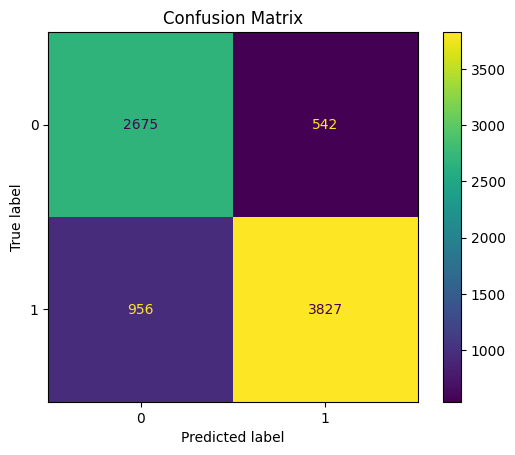

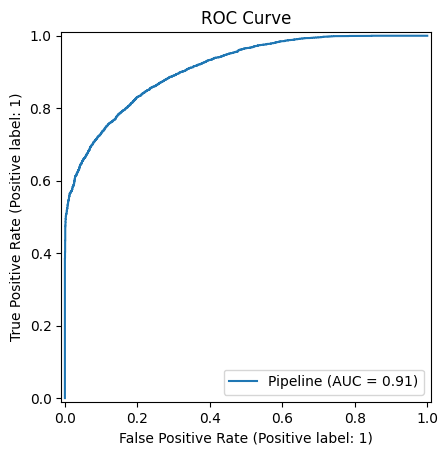

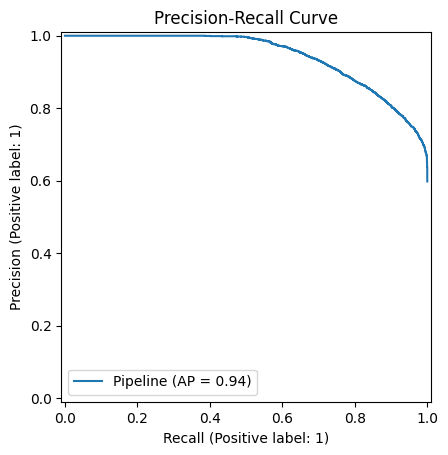

In [20]:
best_report = classification_report_df(best_model, X_valid, y_valid)
display(best_report)

best_report.to_csv(METRICS_DIR / f"{best_model_name}_classification_report.csv")

plot_confusion_matrix(
    best_model,
    X_valid,
    y_valid,
    save_path=FIGURES_DIR / f"{best_model_name}_confusion_matrix.png",
)

plot_roc_curve(
    best_model,
    X_valid,
    y_valid,
    save_path=FIGURES_DIR / f"{best_model_name}_roc_curve.png",
)

plot_pr_curve(
    best_model,
    X_valid,
    y_valid,
    save_path=FIGURES_DIR / f"{best_model_name}_pr_curve.png",
)
